# Starter Code — Stereo Vision dengan 1 HP
Petunjuk persiapan foto, alat, dan hal yang harus dicatat ada di `README.md`. Notebook ini untuk menjalankan kode dan mengisi hasil (foto diambil otomatis dari GitHub `Praktikum_Stereo/Calibration/gmb_*.jpg` dan folder `Stereo`). Jalankan **A → G** berurutan.

## A — Konfigurasi dan pemeriksaan file
Isi tiga nilai yang diukur (`PATTERN_SIZE`, `SQUARE_SIZE_MM`, `BASELINE_CM`). Untuk mengambil foto otomatis dari GitHub di Colab/lokal, pastikan `CLONE_FROM_GITHUB = True`.

In [1]:
from pathlib import Path
import re, csv, math, subprocess
import cv2
import numpy as np
import matplotlib.pyplot as plt

# === ISI SESUAI README ===
PATTERN_SIZE   = (9, 6)     # sudut DALAM (kolom, baris); papan cetak 10 x 7 kotak
SQUARE_SIZE_MM = 25.0       # GANTI dengan ukuran satu kotak hasil penggaris
BASELINE_CM    = 10.0       # GANTI dengan perpindahan pusat kamera L -> R

# === SUMBER DATA (GitHub) ===
REPO_URL = 'https://github.com/Felixriq/-Praktikum_Stereo_Vision.git'
REPO_DIR = Path('repo_stereo')
CLONE_FROM_GITHUB = True          # False bila foto sudah ada di REPO_DIR
DATA_NAME = 'Praktikum_Stereo'    # nama folder di repo (di Linux/Colab huruf besar-kecil berpengaruh)
CAL_NAME  = 'Calibration'

# Foto stereo: None = dideteksi otomatis. Bila otomatis gagal, isi path relatif terhadap folder data,
# contoh: STEREO_LEFT_REL = 'Stereo/left.jpg'
STEREO_LEFT_REL, STEREO_RIGHT_REL = None, None
PAIR_INDEX = 0                    # bila ada beberapa pasang foto stereo, pilih pasangan ke-berapa (mulai 0)

if CLONE_FROM_GITHUB and not REPO_DIR.exists():
    r = subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError('git clone gagal:\n' + r.stderr)

def find_child(parent, name):
    """Cari sub-folder tanpa peduli huruf besar/kecil."""
    for p in parent.iterdir():
        if p.is_dir() and p.name.lower() == name.lower():
            return p
    return None

if not REPO_DIR.exists():
    raise FileNotFoundError(f'Folder {REPO_DIR} tidak ada. Set CLONE_FROM_GITHUB=True atau salin repo ke sana.')
DATA_DIR = find_child(REPO_DIR, DATA_NAME)
if DATA_DIR is None:
    raise FileNotFoundError(f'Folder {DATA_NAME} tidak ada di repo. Isi repo: {[p.name for p in REPO_DIR.iterdir()]}')
CAL_DIR = find_child(DATA_DIR, CAL_NAME)
if CAL_DIR is None:
    raise FileNotFoundError(f'Folder {CAL_NAME} tidak ada. Isi {DATA_DIR}: {[p.name for p in DATA_DIR.iterdir()]}')
OUT = DATA_DIR / 'output'
OUT.mkdir(parents=True, exist_ok=True)

image_ext = {'.jpg', '.jpeg', '.png', '.bmp'}
def nkey(p):                      # urut alami: gmb_2 sebelum gmb_10
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', p.name)]
cal_files = sorted((p for p in CAL_DIR.iterdir() if p.suffix.lower() in image_ext), key=nkey)

# --- cari pasangan foto stereo ---
def is_left(stem):  return re.search(r'(left|kiri|(^|[_\-\s])l($|[_\-\s\d]))', stem.lower()) is not None
def is_right(stem): return re.search(r'(right|kanan|(^|[_\-\s])r($|[_\-\s\d]))', stem.lower()) is not None

if STEREO_LEFT_REL and STEREO_RIGHT_REL:
    pairs = [(DATA_DIR / STEREO_LEFT_REL, DATA_DIR / STEREO_RIGHT_REL)]
else:
    others = [p for p in DATA_DIR.rglob('*')
              if p.is_file() and p.suffix.lower() in image_ext
              and CAL_DIR not in p.parents and OUT not in p.parents]
    by_dir = {}
    for p in others:
        by_dir.setdefault(p.parent, []).append(p)
    pairs = []
    for d, files in sorted(by_dir.items()):
        ls = sorted((f for f in files if is_left(f.stem)), key=nkey)
        rs = sorted((f for f in files if is_right(f.stem)), key=nkey)
        if ls and len(ls) == len(rs):
            pairs.extend(zip(ls, rs))
        elif len(files) == 2:                      # cadangan: dua foto di satu folder -> urut nama
            f = sorted(files, key=nkey)
            print(f'PERHATIAN: nama file tidak jelas kiri/kanan di {d.name}; dianggap {f[0].name}=kiri, {f[1].name}=kanan')
            pairs.append((f[0], f[1]))
    if not pairs:
        print('Gambar non-kalibrasi yang ditemukan:', [str(p.relative_to(DATA_DIR)) for p in others])
        raise FileNotFoundError('Pasangan foto stereo tidak ditemukan otomatis. Isi STEREO_LEFT_REL dan STEREO_RIGHT_REL.')
for i, (a, b) in enumerate(pairs):
    print(f'Pasangan {i}: kiri={a.relative_to(DATA_DIR)} | kanan={b.relative_to(DATA_DIR)}')
L_PATH, R_PATH = pairs[PAIR_INDEX]

print('OpenCV:', cv2.__version__)
print('Foto kalibrasi:', len(cal_files), '| kiri:', L_PATH.exists(), '| kanan:', R_PATH.exists())
print('Kotak:', SQUARE_SIZE_MM, 'mm | baseline:', BASELINE_CM, 'cm')
if SQUARE_SIZE_MM <= 0 or BASELINE_CM <= 0: raise ValueError('Ukuran kotak dan baseline harus positif.')
if len(cal_files) < 10: raise RuntimeError('Sediakan setidaknya 10 foto kalibrasi (disarankan 15–25).')
if not L_PATH.exists() or not R_PATH.exists(): raise FileNotFoundError(f'Periksa {L_PATH} dan {R_PATH}')

Pasangan 0: kiri=Stereo/kiri.jpg | kanan=Stereo/kanan.jpg
OpenCV: 5.0.0
Foto kalibrasi: 20 | kiri: True | kanan: True
Kotak: 25.0 mm | baseline: 10.0 cm


## B — Deteksi sudut chessboard dan ukur jarak dalam piksel
Hasil contoh jarak 2 sudut adalah nilai foto, bukan focal length. Foto gagal atau resolusi berbeda otomatis dilewati.

Resolusi foto kalibrasi: {(2390, 1792): 15, (2400, 1792): 5}
Foto valid: 15 | Gagal: 5
Foto gagal: ['gmb_2.jpg (resolusi berbeda)', 'gmb_6.jpg (resolusi berbeda)', 'gmb_8.jpg (resolusi berbeda)', 'gmb_11.jpg (resolusi berbeda)', 'gmb_12.jpg (resolusi berbeda)']
Contoh jarak dua sudut dalam piksel: 156.4


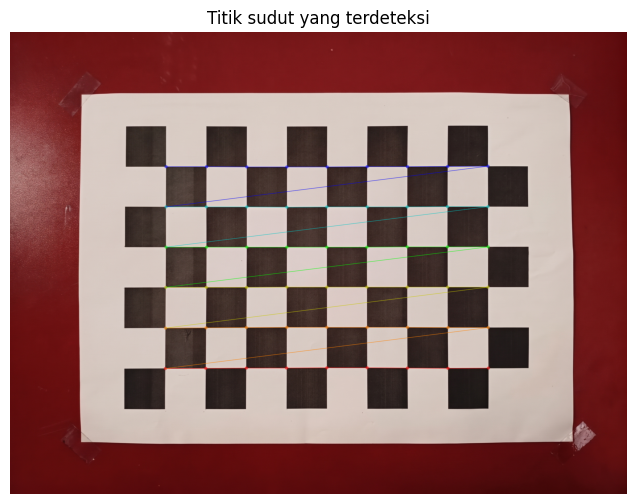

In [2]:
CRIT = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01)

def detect_corners(gray, pattern, det_max=2000):
    """Deteksi di gambar yang diperkecil (cepat), lalu haluskan di resolusi penuh."""
    s = min(1.0, det_max / max(gray.shape))
    small = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else gray
    found, c = cv2.findChessboardCornersSB(small, pattern, flags=cv2.CALIB_CB_NORMALIZE_IMAGE)
    if not found:
        found, c = cv2.findChessboardCorners(
            small, pattern, cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE)
    if not found:
        return False, None
    c = (c.astype(np.float32) / s).reshape(-1, 1, 2)
    c = cv2.cornerSubPix(gray, c, (11, 11), (-1, -1), CRIT)
    return True, c

def read_gray(path):
    img = cv2.imread(str(path))
    return img, (None if img is None else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY))

# Bila pola yang diisi tidak terdeteksi pada foto awal, coba ukuran pola umum lain
probe = [read_gray(p)[1] for p in cal_files[:3]]
probe = [g for g in probe if g is not None]
n_hit = sum(detect_corners(g, PATTERN_SIZE)[0] for g in probe)
if n_hit < max(1, len(probe) - 1):
    print(f'PATTERN_SIZE={PATTERN_SIZE} gagal pada foto awal ({n_hit}/{len(probe)}). Mencoba ukuran lain...')
    cands = sorted({(a, b) for a in range(5, 13) for b in range(4, 10) if a > b},
                   key=lambda t: -(t[0] * t[1]))
    for cand in cands:
        if sum(detect_corners(g, cand)[0] for g in probe) >= max(1, len(probe) - 1):
            print(f'Ukuran pola yang cocok: {cand} -> dipakai. Samakan README/PATTERN_SIZE.')
            PATTERN_SIZE = cand
            break
    else:
        print('Tidak ada ukuran pola yang cocok. Periksa foto: papan harus terlihat utuh dan tidak buram.')

cols, rows = PATTERN_SIZE
obj = np.zeros((cols * rows, 3), np.float32)
obj[:, :2] = np.mgrid[0:cols, 0:rows].T.reshape(-1, 2) * SQUARE_SIZE_MM
objpoints, imgpoints, ok_files, bad_files, spacings = [], [], [], [], []
from collections import Counter
sizes = {}
for path in cal_files:
    im = cv2.imread(str(path))
    if im is not None: sizes[path.name] = (im.shape[1], im.shape[0])
size_count = Counter(sizes.values())
print('Resolusi foto kalibrasi:', dict(size_count))
size_wh = size_count.most_common(1)[0][0]      # resolusi terbanyak dipakai sebagai acuan
preview = None
for path in cal_files:
    img, gray = read_gray(path)
    if img is None:
        bad_files.append(path.name); continue
    wh = (gray.shape[1], gray.shape[0])
    if wh != size_wh:
        bad_files.append(path.name + ' (resolusi berbeda)'); continue
    found, corners = detect_corners(gray, PATTERN_SIZE)
    if not found:
        bad_files.append(path.name); continue
    objpoints.append(obj.copy()); imgpoints.append(corners)
    ok_files.append(path.name)
    spacings.append(float(np.linalg.norm(corners[1, 0] - corners[0, 0])))
    if preview is None:
        preview = img.copy()
        cv2.drawChessboardCorners(preview, PATTERN_SIZE, corners, True)
print('Foto valid:', len(ok_files), '| Gagal:', len(bad_files))
print('Foto gagal:', bad_files)
print('Contoh jarak dua sudut dalam piksel:', round(spacings[0], 2) if spacings else None)
if preview is not None:
    plt.figure(figsize=(10, 6)); plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
    plt.title('Titik sudut yang terdeteksi'); plt.axis('off'); plt.show()
    cv2.imwrite(str(OUT / 'corners_preview.jpg'), preview)
if len(ok_files) < 10: raise RuntimeError('Titik sudut berhasil dideteksi pada <10 foto. Ulangi/ambil foto baru.')

## C — Kalibrasi kamera: hasil fx, fy, cx, cy
Periksa RMS dan simpan hasilnya. Tidak ada angka focal length asumsi. Dua sel berikutnya memeriksa error reproyeksi per foto serta membandingkan skenario penghapusan outlier dan `CALIB_FIX_K3`.

In [3]:
rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, size_wh, None, None)
fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
print('Resolusi kalibrasi:', size_wh)
print('K =\n', K)
print(f'fx={fx:.2f} px | fy={fy:.2f} px | cx={cx:.2f} px | cy={cy:.2f} px')
print(f'RMS reprojection error={rms:.3f} px')
print('Distorsi:', dist.ravel())
np.savez(OUT / 'calibration.npz', K=K, dist=dist, image_wh=size_wh, rms=rms, square_size_mm=SQUARE_SIZE_MM)
if not np.isfinite(rms) or rms > 2.0:
    print('PERHATIAN: RMS cukup besar. Periksa foto kalibrasi dan kesesuaian pola.')

Resolusi kalibrasi: (2390, 1792)
K =
 [[1.85397981e+03 0.00000000e+00 1.19151770e+03]
 [0.00000000e+00 1.85943418e+03 8.88927105e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
fx=1853.98 px | fy=1859.43 px | cx=1191.52 px | cy=888.93 px
RMS reprojection error=0.693 px
Distorsi: [ 1.21217992e-01 -5.16987748e-01 -5.43892932e-04 -4.49609423e-05
  5.16940517e-01]


In [4]:
errs = []
for i in range(len(objpoints)):
    proj, _ = cv2.projectPoints(objpoints[i], rvecs[i], tvecs[i], K, dist)
    d = imgpoints[i].reshape(-1, 2) - proj.reshape(-1, 2)
    errs.append(float(np.sqrt(np.mean(np.sum(d ** 2, axis=1)))))
for n, e in sorted(zip(ok_files, errs), key=lambda t: -t[1]):
    print(n, round(e, 3))
print('Rata-rata:', round(float(np.mean(errs)), 3))

gmb_10.jpg 1.301
gmb_16.jpg 0.997
gmb_13.jpg 0.945
gmb_14.jpg 0.736
gmb_19.jpg 0.631
gmb_1.jpg 0.587
gmb_20.jpg 0.573
gmb_5.jpg 0.547
gmb_9.jpg 0.537
gmb_3.jpg 0.535
gmb_18.jpg 0.524
gmb_7.jpg 0.503
gmb_4.jpg 0.474
gmb_17.jpg 0.464
gmb_15.jpg 0.399
Rata-rata: 0.65


In [5]:
def calib(exclude=(), fix_k3=False):
    idx = [i for i, n in enumerate(ok_files) if n not in exclude]
    flags = cv2.CALIB_FIX_K3 if fix_k3 else 0
    r, K2, d2, _, _ = cv2.calibrateCamera(
        [objpoints[i] for i in idx], [imgpoints[i] for i in idx],
        size_wh, None, None, flags=flags)
    return r, K2, d2.ravel(), len(idx)

# Foto dengan error terbesar dikeluarkan bertahap (otomatis, tidak lagi memakai nama file tetap)
worst = [n for n, _ in sorted(zip(ok_files, errs), key=lambda t: -t[1])]
skenario = [(), tuple(worst[:1]), tuple(worst[:2]), tuple(worst[:4])]
skenario = [ex for ex in skenario if len(ok_files) - len(ex) >= 8]
for ex in skenario:
    for fk in (False, True):
        r, K2, d2, n = calib(ex, fk)
        print(f'foto={n} fix_k3={fk} | RMS={r:.3f} | fx={K2[0,0]:.1f} fy={K2[1,1]:.1f} | '
              f'k1={d2[0]:.3f} k2={d2[1]:.3f} k3={d2[4]:.3f} | dikeluarkan={list(ex)}')

foto=15 fix_k3=False | RMS=0.693 | fx=1854.0 fy=1859.4 | k1=0.121 k2=-0.517 k3=0.517 | dikeluarkan=[]
foto=15 fix_k3=True | RMS=0.725 | fx=1857.1 fy=1862.5 | k1=0.077 k2=-0.226 k3=0.000 | dikeluarkan=[]
foto=14 fix_k3=False | RMS=0.614 | fx=1890.9 fy=1896.5 | k1=0.113 k2=-0.509 k3=0.512 | dikeluarkan=['gmb_10.jpg']
foto=14 fix_k3=True | RMS=0.645 | fx=1889.7 fy=1895.3 | k1=0.070 k2=-0.225 k3=0.000 | dikeluarkan=['gmb_10.jpg']
foto=13 fix_k3=False | RMS=0.579 | fx=1891.1 fy=1896.1 | k1=0.115 k2=-0.498 k3=0.486 | dikeluarkan=['gmb_10.jpg', 'gmb_16.jpg']
foto=13 fix_k3=True | RMS=0.607 | fx=1890.7 fy=1895.7 | k1=0.077 k2=-0.231 k3=0.000 | dikeluarkan=['gmb_10.jpg', 'gmb_16.jpg']
foto=11 fix_k3=False | RMS=0.492 | fx=2044.6 fy=2049.1 | k1=0.159 k2=-0.801 k3=0.987 | dikeluarkan=['gmb_10.jpg', 'gmb_16.jpg', 'gmb_13.jpg', 'gmb_14.jpg']
foto=11 fix_k3=True | RMS=0.545 | fx=2044.0 fy=2048.3 | k1=0.100 k2=-0.336 k3=0.000 | dikeluarkan=['gmb_10.jpg', 'gmb_16.jpg', 'gmb_13.jpg', 'gmb_14.jpg']


## D — Baca stereo, koreksi distorsi, dan cek alignment
Jika foto kiri/kanan tidak cukup sejajar, kode berhenti. Ini bukan stereo rectification penuh. Gunakan objek diam dan rel yang lurus.

PERHATIAN foto kiri: (2400, 1792) -> (2390, 1792) (crop).
PERHATIAN foto kanan: (2400, 1792) -> (2390, 1792) (crop).
Matching: 394 | Inlier: 218
Median beda baris = 2.79 px | Fraksi disparity positif = 100.0%


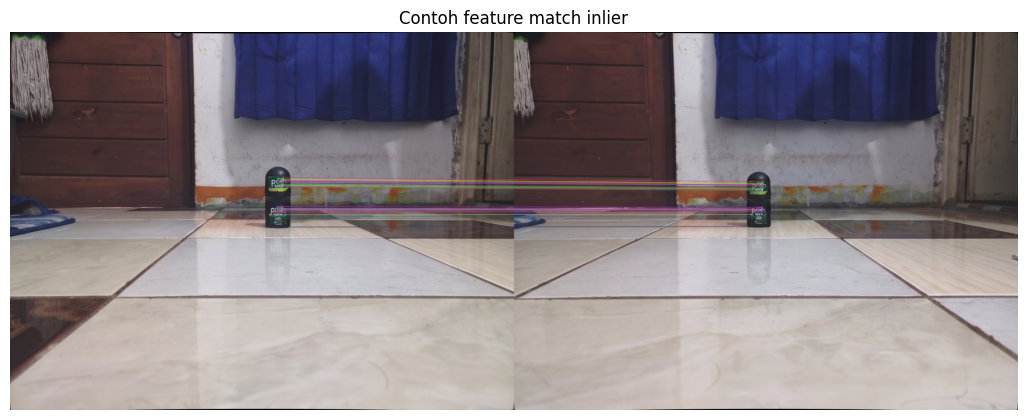

PERINGATAN: alignment kurang baik, hasil depth tidak andal.


In [7]:
STRICT_ALIGNMENT = False   # False = hanya peringatan bila alignment kurang baik (hasil depth jadi kurang andal)

left = cv2.imread(str(L_PATH)); right = cv2.imread(str(R_PATH))
if left is None or right is None: raise ValueError('Gagal membaca foto stereo')
# Samakan ukuran foto stereo dengan foto kalibrasi bila selisihnya kecil (mis. 2400 vs 2390 px).
# Intrinsik K hanya valid untuk ukuran/crop yang sama dengan foto kalibrasi.
FIX_MODE = 'crop'          # 'crop' = potong kelebihan piksel (disarankan) | 'resize' = ubah skala
CROP_ANCHOR_X = 'left'     # sisi yang DIPERTAHANKAN saat memotong lebar: 'left' | 'center' | 'right'
CROP_ANCHOR_Y = 'top'      # sisi yang DIPERTAHANKAN saat memotong tinggi: 'top' | 'center' | 'bottom'
MAX_FIX_FRAC = 0.02        # selisih lebih dari 2% dianggap salah foto/orientasi -> error

def fit_to(img, wh, name):
    h, w = img.shape[:2]
    tw, th = wh
    if (w, h) == (tw, th): return img
    if abs(w - tw) / tw > MAX_FIX_FRAC or abs(h - th) / th > MAX_FIX_FRAC:
        raise ValueError(f'{name}: resolusi {(w, h)} terlalu berbeda dari foto kalibrasi {wh}. '
                         'Cek orientasi portrait/landscape atau gunakan kamera/resolusi yang sama.')
    print(f'PERHATIAN {name}: {(w, h)} -> {wh} ({FIX_MODE}).')
    if FIX_MODE == 'resize':
        return cv2.resize(img, wh, interpolation=cv2.INTER_AREA)
    if w < tw or h < th:     # foto lebih kecil dari acuan: tambahkan tepi tiruan agar ukuran sama
        img = cv2.copyMakeBorder(img, 0, max(0, th - h), 0, max(0, tw - w), cv2.BORDER_REPLICATE)
        h, w = img.shape[:2]
    ox = {'left': 0, 'center': (w - tw) // 2, 'right': w - tw}[CROP_ANCHOR_X]
    oy = {'top': 0, 'center': (h - th) // 2, 'bottom': h - th}[CROP_ANCHOR_Y]
    return img[oy:oy + th, ox:ox + tw]

left = fit_to(left, size_wh, 'foto kiri')
right = fit_to(right, size_wh, 'foto kanan')
# Undistort mempertahankan koordinat intrinsik K (P=K)
map1, map2 = cv2.initUndistortRectifyMap(K, dist, None, K, size_wh, cv2.CV_32FC1)
left_u = cv2.remap(left, map1, map2, cv2.INTER_LINEAR)
right_u = cv2.remap(right, map1, map2, cv2.INTER_LINEAR)
lg = cv2.cvtColor(left_u, cv2.COLOR_BGR2GRAY)
rg = cv2.cvtColor(right_u, cv2.COLOR_BGR2GRAY)
orb = cv2.ORB_create(nfeatures=4500)
k1, des1 = orb.detectAndCompute(lg, None)
k2, des2 = orb.detectAndCompute(rg, None)
if des1 is None or des2 is None or len(k1) < 2 or len(k2) < 2:
    raise RuntimeError('Fitur foto kurang. Gunakan objek/latar bertekstur.')
matches = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(des1, des2, k=2)
good = [m[0] for m in matches if len(m) == 2 and m[0].distance < 0.75 * m[1].distance]
if len(good) < 20: raise RuntimeError('Terlalu sedikit feature match. Ulangi foto dengan lebih banyak tekstur.')
pL = np.float32([k1[m.queryIdx].pt for m in good]); pR = np.float32([k2[m.trainIdx].pt for m in good])
# Fundamental matrix hanya untuk filter outlier, bukan mengganti rectification
F, mask = cv2.findFundamentalMat(pL, pR, cv2.FM_RANSAC, 1.5, 0.99)
if F is None or mask is None: raise RuntimeError('RANSAC gagal: pasangan foto sulit dicocokkan.')
inlier = mask.ravel().astype(bool)
if inlier.sum() < 15: raise RuntimeError('Inlier kurang dari 15. Ulangi foto.')
dy = np.abs(pL[inlier, 1] - pR[inlier, 1])
dx = pL[inlier, 0] - pR[inlier, 0]
median_dy = float(np.median(dy)); positive_fraction = float(np.mean(dx > 0))
print('Matching:', len(good), '| Inlier:', int(inlier.sum()))
print(f'Median beda baris = {median_dy:.2f} px | Fraksi disparity positif = {positive_fraction:.1%}')
vis = cv2.drawMatches(left_u, k1, right_u, k2, [m for m, v in zip(good, inlier) if v][:40], None,
                      flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(13, 5)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('Contoh feature match inlier'); plt.axis('off'); plt.show()
cv2.imwrite(str(OUT / 'matches.jpg'), vis)
ALIGNMENT_OK = (median_dy <= 2.0 and positive_fraction >= 0.70)
if ALIGNMENT_OK:
    print('Alignment lolos pemeriksaan awal (bukan jaminan rectification sempurna).')
elif STRICT_ALIGNMENT:
    raise RuntimeError('Alignment belum cukup baik. Ulangi foto stereo tanpa rotasi/naik-turun; '
                       'jangan pakai hasil depth. (Atau set STRICT_ALIGNMENT=False hanya untuk eksplorasi.)')
else:
    print('PERINGATAN: alignment kurang baik, hasil depth tidak andal.')

## E — Hitung disparity dan depth map
Untuk melihat hasil, objek dekat biasanya memiliki disparity lebih besar. Nilai tak valid dibiarkan sebagai `NaN`.

Skala=0.536 | ukuran SGBM=1280x960 | fx_skala=992.9 | numDisparities=208
Piksel disparity valid: 42.2%


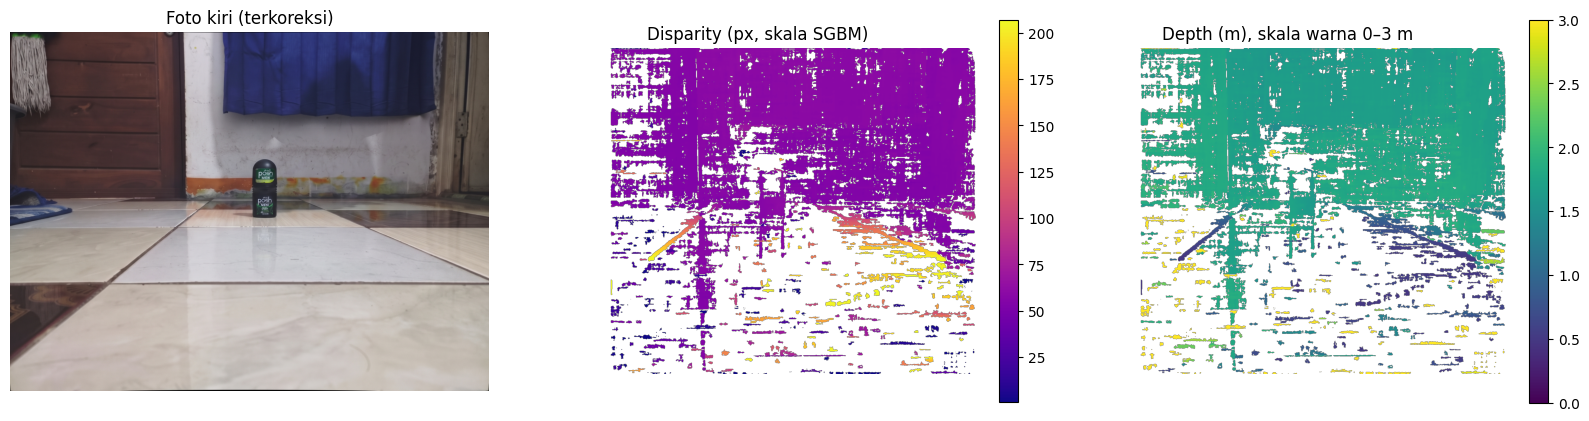

True

In [8]:
if STRICT_ALIGNMENT and not ALIGNMENT_OK: raise RuntimeError('Alignment belum lolos.')

# Foto beresolusi tinggi diperkecil agar SGBM cepat dan tidak kehabisan memori.
# fx ikut diskalakan, sehingga Z = fx*B/d tetap benar.
TARGET_W = 1280
SCALE = min(1.0, TARGET_W / left_u.shape[1])
def shrink(a): return cv2.resize(a, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_AREA) if SCALE < 1 else a
ls, rs, left_s = shrink(lg), shrink(rg), shrink(left_u)
fx_s = float(fx) * SCALE

# numDisparities (kelipatan 16) harus mencakup disparity objek terdekat: d = fx*B/Z
NEAREST_Z_M = 0.5
need = fx_s * (BASELINE_CM / 100.0) / NEAREST_Z_M
SGBM_NUM_DISPARITIES = int(min(512, max(64, math.ceil(need / 16) * 16)))
SGBM_BLOCK_SIZE = 7
print(f'Skala={SCALE:.3f} | ukuran SGBM={ls.shape[1]}x{ls.shape[0]} | fx_skala={fx_s:.1f} | numDisparities={SGBM_NUM_DISPARITIES}')

sgbm = cv2.StereoSGBM_create(
    minDisparity=0, numDisparities=SGBM_NUM_DISPARITIES,
    blockSize=SGBM_BLOCK_SIZE,
    P1=8 * 1 * SGBM_BLOCK_SIZE ** 2, P2=32 * 1 * SGBM_BLOCK_SIZE ** 2,
    uniquenessRatio=10, speckleWindowSize=70, speckleRange=2,
    disp12MaxDiff=1, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
raw = sgbm.compute(ls, rs).astype(np.float32)
disp = raw / 16.0
valid = np.isfinite(disp) & (disp > 0.5)
Z = np.full(disp.shape, np.nan, np.float32)
Z[valid] = (fx_s * (BASELINE_CM / 100.0)) / disp[valid]
print(f'Piksel disparity valid: {valid.mean() * 100:.1f}%')
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(cv2.cvtColor(left_s, cv2.COLOR_BGR2RGB)); ax[0].set_title('Foto kiri (terkoreksi)')
a = ax[1].imshow(np.ma.masked_invalid(np.where(valid, disp, np.nan)), cmap='plasma')
ax[1].set_title('Disparity (px, skala SGBM)'); fig.colorbar(a, ax=ax[1], fraction=.04)
b = ax[2].imshow(np.ma.masked_invalid(Z), cmap='viridis', vmin=0, vmax=3)
ax[2].set_title('Depth (m), skala warna 0–3 m'); fig.colorbar(b, ax=ax[2], fraction=.04)
for x in ax: x.axis('off')
plt.tight_layout(); plt.show()
np.save(OUT / 'disparity_px.npy', np.where(valid, disp, np.nan))
np.save(OUT / 'depth_m.npy', Z)
np.savez(OUT / 'stereo_meta.npz', scale=SCALE, fx_scaled=fx_s, baseline_cm=BASELINE_CM, num_disp=SGBM_NUM_DISPARITIES)
cv2.imwrite(str(OUT / 'left_undistorted.jpg'), left_u)

## F — Ukur satu objek pada ROI
Pilih satu objek bertekstur (otomatis pada area tulisan/label dengan `ROI_MODE = 'auto'` atau manual lewat `ROI_X`, `ROI_Y`) dan bandingkan hasil depth estimasi dengan jarak meteran (`Z_TRUE_M`). Sel kedua menampilkan zoom area sekitar ROI.

ROI manual (antara o & s tulisan posh badan botol): (1267, 846) pada gambar 2390x1792
ROI=(1267,846) | disparity ROI=59.88 px | Z estimasi=1.658 m | meteran=1.000 m | error=65.83%


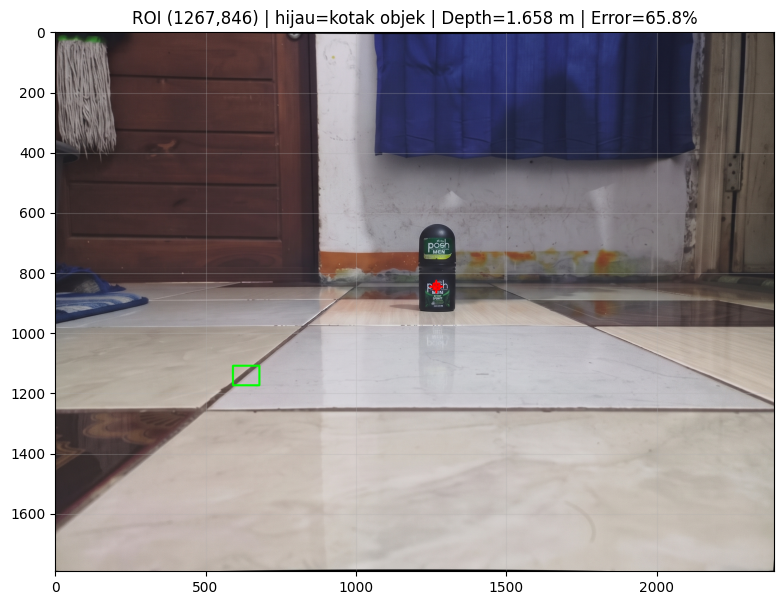

In [10]:
# === ISI HASIL PENGAMATAN ===
ROI_MODE = 'manual'   # 'manual' = kunci tepat di antara huruf 'o' dan 's' tulisan posh (badan botol)
ROI_X_FRAC = 636 / 1200   # posisi x=636 pada resolusi 1200x896
ROI_Y_FRAC = 423 / 896    # posisi y=423 pada resolusi 1200x896
ROI_RADIUS = 10       # jendela (2*r+1) piksel pada resolusi asli
Z_TRUE_M = 1.0        # GANTI: jarak sebenarnya dari meteran (meter)

H_full, W_full = left_u.shape[:2]
h, w = Z.shape

# Koordinat tepat di antara 'o' dan 's' pada label "posh" di badan botol
ROI_X = int(round(ROI_X_FRAC * W_full))
ROI_Y = int(round(ROI_Y_FRAC * H_full))

def auto_roi(disp, valid, gray_s, scale, roi_radius_full=10):
    """Deteksi otomatis titik ROI pada area tulisan/label bertekstur tinggi di objek foreground (botol)."""
    hh, ww = disp.shape
    x_min, x_max = int(ww * 0.15), int(ww * 0.85)
    y_min, y_max = int(hh * 0.08), int(hh * 0.82)
    zone = np.zeros((hh, ww), dtype=bool)
    zone[y_min:y_max, x_min:x_max] = True

    zv = valid & zone
    if zv.sum() < 100:
        return None

    disp_fill = np.where(valid, disp, 0.0).astype(np.float32)
    disp_med = cv2.medianBlur(disp_fill, 5)
    vals = disp_med[zv]

    d_bg = float(np.median(vals))
    fg_gap = max(2.5, 0.15 * d_bg)
    min_area = max(60, int(0.0005 * hh * ww))

    fg = (valid & zone & (disp_med >= d_bg + fg_gap)).astype(np.uint8)
    fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11)))
    if int(fg.sum()) < min_area:
        d_ref = float(np.percentile(vals, 75.0))
        tol = max(3.0, 0.12 * d_ref)
        fg = (valid & zone & (np.abs(disp_med - d_ref) <= tol)).astype(np.uint8)
        fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
        fg = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11)))
    if int(fg.sum()) < min_area:
        return None

    d_hi = float(np.percentile(disp_med[fg > 0], 95.0))

    k_stroke = max(5, int(round(ww * 0.009)) | 1)
    ker_stroke = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_stroke, k_stroke))
    bh = cv2.morphologyEx(gray_s, cv2.MORPH_BLACKHAT, ker_stroke).astype(np.float32)
    th_img = cv2.morphologyEx(gray_s, cv2.MORPH_TOPHAT, ker_stroke).astype(np.float32)
    stroke = bh + th_img

    gx = cv2.Sobel(gray_s, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray_s, cv2.CV_32F, 0, 1, ksize=3)
    grad = cv2.magnitude(gx, gy)

    s_norm = stroke / (float(np.percentile(stroke[zone], 99.0)) + 1e-6)
    g_norm = grad / (float(np.percentile(grad[zone], 99.0)) + 1e-6)
    text_raw = np.clip(0.65 * s_norm + 0.35 * g_norm, 0.0, 2.0)
    k_blk = max(15, int(round(ww * 0.025)) | 1)
    text_energy = cv2.GaussianBlur(text_raw, (k_blk, k_blk), 0)

    yy, xx = np.mgrid[0:hh, 0:ww].astype(np.float32)
    center_w = np.exp(-0.5 * (((xx - ww * 0.50) / (ww * 0.28)) ** 2 + ((yy - hh * 0.48) / (hh * 0.28)) ** 2))

    rr_s = max(3, int(round(roi_radius_full * scale)))
    k_var = max(5, (2 * rr_s + 1) | 1)
    m1 = cv2.boxFilter(disp_fill, cv2.CV_32F, (k_var, k_var))
    m2 = cv2.boxFilter(disp_fill * disp_fill, cv2.CV_32F, (k_var, k_var))
    disp_std = np.sqrt(np.maximum(0.0, m2 - m1 * m1))
    valid_frac = cv2.boxFilter(valid.astype(np.float32), cv2.CV_32F, (k_var, k_var))
    stab_w = (1.0 / (1.0 + disp_std)) * (valid_frac >= 0.7).astype(np.float32)

    n, lab, stats, _ = cv2.connectedComponentsWithStats(fg, connectivity=8)
    dist_cap = max(8.0, ww * 0.015)
    best_result = None
    best_score = -1.0

    for cid in range(1, n):
        area = int(stats[cid, cv2.CC_STAT_AREA])
        if area < min_area:
            continue
        comp_mask = (lab == cid).astype(np.uint8)
        dist_in = cv2.distanceTransform(comp_mask, cv2.DIST_L2, 5)
        max_dist = float(dist_in.max())
        if max_dist < 1.5:
            continue

        min_margin = min(float(rr_s + 1), 0.45 * max_dist)
        interior = (dist_in >= max(1.0, min_margin)) & valid
        if interior.sum() < 15:
            interior = (comp_mask > 0) & valid
        if interior.sum() < 10:
            continue

        dist_w = np.clip(dist_in / (min(max_dist, dist_cap) + 1e-6), 0.0, 1.0) ** 0.6
        pix_score = text_energy * (0.25 + 0.75 * dist_w) * stab_w * (0.4 + 0.6 * center_w)
        pix_score = np.where(interior, pix_score, -1.0)
        if float(pix_score.max()) <= 0:
            pix_score = np.where(interior, text_energy * (0.25 + 0.75 * dist_w) * (0.4 + 0.6 * center_w), -1.0)

        peak_idx = int(np.argmax(pix_score))
        peak_val = float(pix_score.ravel()[peak_idx])
        if peak_val <= 0:
            continue

        py_s, px_s = divmod(peak_idx, ww)
        d_peak = float(disp_med[py_s, px_s])
        comp_score = peak_val * (0.5 + 0.5 * min(1.0, d_peak / (d_hi + 1e-6))) * np.log1p(area)
        if comp_score > best_score:
            best_score = comp_score
            best_result = (cid, px_s, py_s, d_peak, comp_mask)

    if best_result is None:
        return None

    _, bx_s, by_s, d_peak, comp_mask = best_result

    tol_c = max(2.5, 0.10 * d_peak)
    tight = ((comp_mask > 0) & valid & (np.abs(disp_med - d_peak) <= tol_c)).astype(np.uint8)
    tight = cv2.morphologyEx(tight, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    _, tlab = cv2.connectedComponents(tight, connectivity=8)
    seed_id = int(tlab[by_s, bx_s])
    obj_mask = (tlab == seed_id) if seed_id > 0 else (comp_mask > 0)
    ys, xs = np.where(obj_mask)
    x0, y0 = int(xs.min()), int(ys.min())
    bw, bh = int(xs.max() - x0 + 1), int(ys.max() - y0 + 1)

    return dict(
        x=bx_s / scale,
        y=by_s / scale,
        box=(x0, y0, bw, bh),
        d_ref=d_peak,
        d_bg=d_bg,
    )

# Tetap jalankan auto_roi untuk menggambar kotak hijau objek, tapi ROI tetap pakai titik manual
res = auto_roi(disp, valid, ls, SCALE, ROI_RADIUS)
obj_box = res['box'] if res is not None else None
if ROI_MODE == 'auto' and res is not None:
    ROI_X, ROI_Y = int(round(res['x'])), int(round(res['y']))
    print(f'ROI otomatis (area tulisan): ({ROI_X}, {ROI_Y}) | disparity latar={res["d_bg"]:.1f} px | '
          f'disparity objek={res["d_ref"]:.1f} px | kotak objek (skala SGBM)={obj_box}')
else:
    print(f'ROI manual (antara o & s tulisan posh badan botol): ({ROI_X}, {ROI_Y}) pada gambar {W_full}x{H_full}')

if not (0 <= ROI_X < W_full and 0 <= ROI_Y < H_full):
    raise ValueError(f'ROI ({ROI_X},{ROI_Y}) di luar gambar {W_full}x{H_full}.')
rx, ry = int(round(ROI_X * SCALE)), int(round(ROI_Y * SCALE))     # ke koordinat SGBM
rr = max(3, int(round(ROI_RADIUS * SCALE)))
x0, x1 = max(0, rx - rr), min(w, rx + rr + 1)
y0, y1 = max(0, ry - rr), min(h, ry + rr + 1)
roi_z = Z[y0:y1, x0:x1]; roi_d = disp[y0:y1, x0:x1]
mask_roi = np.isfinite(roi_z) & (roi_z > 0)
if mask_roi.sum() < 10: raise RuntimeError('ROI memiliki <10 piksel depth valid. Pilih area lain (ROI_MODE="manual").')
Z_EST = float(np.median(roi_z[mask_roi]))
D_MED = float(np.median(roi_d[mask_roi]))
if Z_TRUE_M <= 0: raise ValueError('Jarak meteran harus positif.')
ERROR_PCT = abs(Z_EST - Z_TRUE_M) / Z_TRUE_M * 100
print(f'ROI=({ROI_X},{ROI_Y}) | disparity ROI={D_MED:.2f} px | Z estimasi={Z_EST:.3f} m | meteran={Z_TRUE_M:.3f} m | error={ERROR_PCT:.2f}%')

shown = cv2.cvtColor(left_u, cv2.COLOR_BGR2RGB).copy()
th = max(3, W_full // 400)
if obj_box is not None:
    bx, by, bw_, bh_ = obj_box
    cv2.rectangle(shown, (int(bx / SCALE), int(by / SCALE)), (int((bx + bw_) / SCALE), int((by + bh_) / SCALE)), (0, 255, 0), th)
cv2.rectangle(shown, (int(x0 / SCALE), int(y0 / SCALE)), (int((x1 - 1) / SCALE), int((y1 - 1) / SCALE)), (255, 0, 0), th)
cv2.drawMarker(shown, (ROI_X, ROI_Y), (255, 0, 0), cv2.MARKER_CROSS, th * 8, th)
plt.figure(figsize=(10, 7)); plt.imshow(shown)
plt.grid(True, alpha=0.25)
plt.title(f'ROI ({ROI_X},{ROI_Y}) | hijau=kotak objek | Depth={Z_EST:.3f} m | Error={ERROR_PCT:.1f}%'); plt.show()

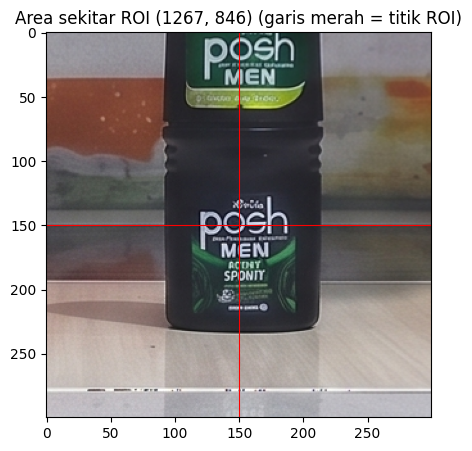

In [11]:
half = 150
xa, xb = max(0, ROI_X - half), min(W_full, ROI_X + half)
ya, yb = max(0, ROI_Y - half), min(H_full, ROI_Y + half)
crop = left_u[ya:yb, xa:xb]
plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.axvline(ROI_X - xa, color='red', lw=0.8); plt.axhline(ROI_Y - ya, color='red', lw=0.8)
plt.title(f'Area sekitar ROI ({ROI_X}, {ROI_Y}) (garis merah = titik ROI)'); plt.show()

## G — Simpan satu baris percobaan
Simpan satu baris hasil percobaan ke `hasil_pengukuran.csv`. Ubah `TEST_ID` (misalnya `uji_01`, `uji_02`, `uji_03`) setiap kali menguji variasi jarak atau baseline.

In [12]:
TEST_ID = 'uji_02'  # GANTI: uji_01, uji_02, uji_03
csv_path = OUT / 'hasil_pengukuran.csv'
record = {
    'uji': TEST_ID, 'baseline_cm': BASELINE_CM, 'square_size_mm': SQUARE_SIZE_MM,
    'fx_px': round(float(fx), 3), 'fy_px': round(float(fy), 3),
    'rms_px': round(float(rms), 3), 'median_vertical_error_px': round(median_dy, 3),
    'disparity_roi_px': round(D_MED, 3), 'depth_est_m': round(Z_EST, 4),
    'depth_meter_m': round(Z_TRUE_M, 4), 'error_pct': round(ERROR_PCT, 2)}
rows = []
if csv_path.exists():
    with csv_path.open(encoding='utf-8', newline='') as fh: rows = list(csv.DictReader(fh))
rows = [r for r in rows if r['uji'] != TEST_ID] + [record]
with csv_path.open('w', encoding='utf-8', newline='') as fh:
    writer = csv.DictWriter(fh, fieldnames=list(record), extrasaction='ignore')
    writer.writeheader(); writer.writerows(rows)
print('Tersimpan:', csv_path)
for r in rows: print(r['uji'], '| jarak meteran', r['depth_meter_m'], 'm | estimasi', r['depth_est_m'], 'm | error', r['error_pct'], '%')

Tersimpan: repo_stereo/Praktikum_Stereo/output/hasil_pengukuran.csv
uji_02 | jarak meteran 1.0 m | estimasi 1.6583 m | error 65.83 %


## Tugas analisis dan flowchart
1. Buat minimal 3 percobaan dengan variasi jarak objek atau variasi baseline.
2. Plot grafik error (%) terhadap jarak sebenarnya dan/atau baseline.
3. Tuliskan 3 faktor utama yang menyebabkan perbedaan jarak estimasi dan jarak sebenarnya pada percobaan Anda.
4. Lampirkan 1 hasil visual: gambar kiri + ROI, disparity map, dan depth map.
5. Buat flowchart alur kerja sistem (kalibrasi → koreksi distorsi → disparity → estimasi jarak → evaluasi error).